# 공장 설비 고장 예측 — 센서 5개로 고장을 잡을 수 있을까?
**피지컬AI응용 (MR347) · 2026-2 · 데이터 분석 프로젝트**

데이터: AI4I 2020 Predictive Maintenance Dataset (UCI · Kaggle 공개, 합성 데이터)
https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

모델: **결정트리** 하나 · 순서: ① 데이터 → ② 나누기 → ③ 깊이 고르기 → ④ 평가 → ⑤ 결론

In [1]:
%pip install -q koreanize-matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. 데이터 불러오기
밀링 머신 운전 기록 1만 건 — 입력: 센서 5개, 정답: `Machine failure` (0 정상 / 1 고장)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib                      # 그래프 한글 깨짐 방지
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"
df = pd.read_csv(URL)
print(df.shape, "| 결측치", df.isna().sum().sum())
print(df["Machine failure"].value_counts())
df.head()

(10000, 14) | 결측치 0
Machine failure
0    9661
1     339
Name: count, dtype: int64


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. 입력 · 정답 나누기
센서 5개만 입력으로 쓴다. 고장 유형 열(TWF · HDF · PWF · OSF · RNF)은 고장이 **난 뒤에** 붙는 꼬리표라 넣으면 정답을 미리 보는 셈(누수)이다.

In [3]:
sensors = ["Air temperature [K]", "Process temperature [K]",
           "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
X = df[sensors]
y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # 고장 비율을 양쪽에 똑같이
print("훈련", X_train.shape, "| 시험", X_test.shape, "| 시험 속 고장", y_test.sum(), "건")

훈련 (8000, 5) | 시험 (2000, 5) | 시험 속 고장 68 건


## 3. 트리 깊이 고르기 — 훈련 데이터로 5겹 교차검증
고장이 3.4% 뿐이라 **"전부 정상" 이라고만 해도 정확도 96.6%** — 정확도 대신 **재현율**(실제 고장 중 잡은 비율)과 **F1** 을 본다.
시험 데이터는 마지막 평가에 한 번만 쓴다.

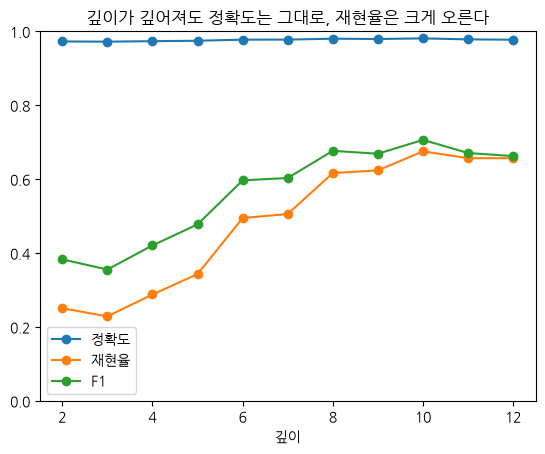

,깊이,정확도,재현율,F1
0,2,0.973,0.251,0.383
1,3,0.972,0.229,0.356
2,4,0.973,0.288,0.421
3,5,0.975,0.343,0.478
4,6,0.978,0.495,0.597
5,7,0.978,0.506,0.603
6,8,0.980,0.616,0.677
7,9,0.979,0.624,0.669
8,10,0.981,0.675,0.706
9,11,0.978,0.657,0.671


In [4]:
rows = []
for depth in range(2, 13):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    cv = cross_validate(tree, X_train, y_train, cv=5, scoring=["accuracy", "recall", "f1"])
    rows.append({"깊이": depth, "정확도": cv["test_accuracy"].mean(),
                 "재현율": cv["test_recall"].mean(), "F1": cv["test_f1"].mean()})
result = pd.DataFrame(rows)

result.plot(x="깊이", y=["정확도", "재현율", "F1"], marker="o", ylim=(0, 1))
plt.title("깊이가 깊어져도 정확도는 그대로, 재현율은 크게 오른다")
plt.show()
result.round(3)

## 4. 시험 데이터로 평가 — F1 이 가장 높은 깊이

In [5]:
best = int(result.loc[result["F1"].idxmax(), "깊이"])
tree = DecisionTreeClassifier(max_depth=best, random_state=42).fit(X_train, y_train)
pred = tree.predict(X_test)

print("고른 깊이:", best)
print("전부 '정상' 정확도:", round(1 - y_test.mean(), 3))
print(f"결정트리 정확도 {accuracy_score(y_test, pred):.3f}  재현율 {recall_score(y_test, pred):.3f}  F1 {f1_score(y_test, pred):.3f}")
print(confusion_matrix(y_test, pred))          # [[정상→정상, 정상→고장], [고장→정상, 고장→고장]]

고른 깊이: 10
전부 '정상' 정확도: 0.966
결정트리 정확도 0.981  재현율 0.647  F1 0.698
[[1918   14]
 [  24   44]]


In [6]:
# 트리가 어떤 센서를 많이 썼나
pd.Series(tree.feature_importances_, index=sensors).sort_values(ascending=False).round(3)

Torque [Nm]                0.384
Air temperature [K]        0.238
Tool wear [min]            0.140
Rotational speed [rpm]     0.119
Process temperature [K]    0.119
dtype: float64

## 5. 결론
1. **정확도는 속인다** — 고장이 3.4% 라 "전부 정상" 도 0.966. 재현율로 봐야 차이가 보인다.
2. **깊이를 교차검증으로 고르면** 재현율이 얕은 트리보다 크게 오른다.
3. 그래도 놓치는 고장이 남는다 — 센서 값만으로는 한계가 있다.

**한계** — 합성 데이터라 실제 공장 성능은 보장할 수 없고, 시점 정보가 없어 "언제" 고장 날지는 모른다.